# Predicting King County house prices with a neural network

**Team:** Karthikeyan Saravanan, Emmanuel Marquez, Bars Babila, Samiha Abeda Nur
**Course:** AI Methods I – Day 4: Neural networks and computer vision (IAAC MaAI 2026/27)
**Track:** A1 – a multilayer perceptron (MLP) on tabular data

On Day 2 we predicted the sale price of a house in King County (Washington, USA) with classic machine-learning models, and gradient boosting won. Today we train a **neural network** on **exactly the same data, inputs, target and test set**, and ask one question: **is the network better than our Day 2 model?**

# 0. Introduction and problem definition

## 0.1 Use case: the three questions of the brief

- **Who would use this model, and for what?** Real estate professionals, buyers and lenders who want a **quick first estimate** of what a house in King County is worth, from a few facts about the building and its location, before a full professional valuation. This is the same use case as our Day 2 model.
- **What does a mistake cost?** Over-estimating the price can make a buyer overpay or a lender lend too much; under-estimating it can make a seller sell too cheaply. Both directions are costly, and an error of 50,000 USD matters much more for a 250,000 USD house than for a 1,500,000 USD one. So we care about the error **in percent**, not in dollars. This is why we predict `log10(price)`, as on Day 2, and report the error as a typical percentage.
- **What would be good enough?** We compare the network with two models on the same test set: a **dummy model** that always predicts the average price (the floor), and our **Day 2 gradient boosting model** (the bar to beat). A network that only matches the Day 2 model would still be a useful result: it tells us whether the extra work of deep learning pays off on this kind of data.

## 0.2 The data

We use [House Sales in King County, USA](https://www.kaggle.com/datasets/harlfoxem/housesalesprediction) (Kaggle, licence CC0 1.0, public domain), as cleaned in our [Day 1 / Day 2 assignment](https://github.com/iaac-maai/2-day2-assignment). It contains **20,703 sales** of houses in King County, which includes Seattle, between May 2014 and May 2015, with 19 columns. **One example is one sale**: one row with the building's characteristics, its location and its sale price.

The Day 1 cleaning converted the dates, removed the `waterfront` and `view` columns (mostly zeros) and filtered extreme prices, living areas and bedroom counts. We do not clean the data again: using the **same rows** as on Day 2 is what makes the comparison fair.

## 0.3 Setup

The notebook lives in `notebook/`, so the other folders are **one level up**: all paths are relative and start from `Path("..")`. A fixed `RANDOM_STATE = 42` is used everywhere randomness is involved, including PyTorch, so a re-run gives the same results.

In [3]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install -r ../requirements.txt

In [4]:
import copy
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [5]:
# --- Folders (the notebook lives in notebook/, the rest is one level up) ------
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

# --- Display and plot settings (same as Days 1-3) ----------------------------
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# --- The same seed everywhere -------------------------------------------------
# Networks start from random weights, so fixing the seed gives everybody the same results
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# --- Which processor will train the network? ----------------------------------
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print(f"PyTorch {torch.__version__}, using device: {DEVICE}")


def save_fig(name, also_to_models=False):
    # Save the current figure as a PNG in figures/ (and in models/ if it goes in the model card)
    for folder in [FIG_DIR] + ([MODEL_DIR] if also_to_models else []):
        path = folder / f"{name}.png"
        plt.savefig(path, dpi=150, bbox_inches="tight")
        print(f"Figure saved to {path}")

PyTorch 2.14.1+cpu, using device: cpu


# 1. Data and splits

## 1.1 Load the data

We load the cleaned file from our public Day 2 repository. The first time, the notebook downloads it and stores a copy in `data/` (which is not committed to GitHub).

In [6]:
CLEAN_URL = "https://raw.githubusercontent.com/iaac-maai/2-day2-assignment/main/data/kc_houses_data_clean.csv"
CLEAN_PATH = DATA_DIR / "kc_houses_data_clean.csv"

if not CLEAN_PATH.exists():
    pd.read_csv(CLEAN_URL).to_csv(CLEAN_PATH, index=False)
    print(f"Downloaded to {CLEAN_PATH}")

houses = pd.read_csv(CLEAN_PATH, parse_dates=["date"])
print(f"{houses.shape[0]:,} sales, {houses.shape[1]} columns")
print(f"Sales from {houses['date'].min():%Y-%m-%d} to {houses['date'].max():%Y-%m-%d}")
print(f"Missing values: {houses.isna().sum().sum()}, duplicated rows: {houses.duplicated().sum()}")
houses.head()

Downloaded to ..\data\kc_houses_data_clean.csv
20,703 sales, 19 columns
Sales from 2014-05-02 to 2015-05-27
Missing values: 0, duplicated rows: 0


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,2014-10-13,"221,900.000",3,1.000,1180,5650,1.000,3,7,1180,0,1955,0,98178,47.511,-122.257,1340,5650
1,6414100192,2014-12-09,"538,000.000",3,2.250,2570,7242,2.000,3,7,2170,400,1951,1991,98125,47.721,-122.319,1690,7639
2,5631500400,2015-02-25,"180,000.000",2,1.000,770,10000,1.000,3,6,770,0,1933,0,98028,47.738,-122.233,2720,8062
3,2487200875,2014-12-09,"604,000.000",4,3.000,1960,5000,1.000,5,7,1050,910,1965,0,98136,47.521,-122.393,1360,5000
4,1954400510,2015-02-18,"510,000.000",3,2.000,1680,8080,1.000,3,8,1680,0,1987,0,98074,47.617,-122.045,1800,7503


## 1.2 Inputs and target: the same as on Day 2

To compare the network with our Day 2 model fairly, we keep **every choice of Day 2**:

- **Target:** `log10(price)`. Prices are right-skewed, and an error on the log scale is an error in **percent** (see the use case). A log10 error of 0.05 means a factor of 10^0.05 = 1.12, so the prediction is about 12% too high or too low.
- **Inputs (13 columns):** the building (`bedrooms`, `bathrooms`, `sqft_living`, `sqft_lot`, `floors`, `condition`, `grade`, `sqft_basement`, `yr_built`, `yr_renovated`) and its location (`zipcode`, `lat`, `long`).
- **Dropped, as on Day 2:** `id` and `date` (identifiers, not characteristics), `sqft_above` (= `sqft_living − sqft_basement`, so it repeats information), and `sqft_living15` / `sqft_lot15` (they describe the neighbours, not the house).

In [7]:
TARGET = "price"
NUMERIC_COLUMNS = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
                   "condition", "grade", "sqft_basement", "yr_built", "yr_renovated",
                   "lat", "long"]
NOMINAL_COLUMNS = ["zipcode"]
INPUT_COLUMNS = NUMERIC_COLUMNS + NOMINAL_COLUMNS

X = houses[INPUT_COLUMNS]
y = np.log10(houses[TARGET])          # the target: log10 of the price in USD
groups = houses["id"]                 # only used to build the splits, not as an input

print(f"X: {X.shape[0]:,} rows x {X.shape[1]} columns")
print(f"Skewness of price: {houses[TARGET].skew():.2f}, of log10(price): {y.skew():.2f}")
X.describe().T

X: 20,703 rows x 13 columns
Skewness of price: 1.72, of log10(price): 0.28


,count,mean,std,min,25%,50%,75%,max
bedrooms,"20,703.000",3.381,0.836,2.000,3.000,3.000,4.000,6.000
bathrooms,"20,703.000",2.108,0.715,0.500,1.750,2.250,2.500,5.250
sqft_living,"20,703.000","2,053.138",799.705,720.000,"1,445.000","1,920.000","2,520.000","4,970.000"
sqft_lot,"20,703.000","14,649.509","39,056.371",520.000,"5,027.000","7,579.000","10,500.000","1,651,359.000"
floors,"20,703.000",1.496,0.540,1.000,1.000,1.500,2.000,3.500
condition,"20,703.000",3.413,0.647,1.000,3.000,3.000,4.000,5.000
grade,"20,703.000",7.647,1.086,4.000,7.000,7.000,8.000,13.000
sqft_basement,"20,703.000",284.345,422.543,0.000,0.000,0.000,560.000,"2,350.000"
yr_built,"20,703.000","1,971.491",29.151,"1,900.000","1,952.000","1,976.000","1,997.000","2,015.000"
yr_renovated,"20,703.000",81.946,396.053,0.000,0.000,0.000,0.000,"2,015.000"


We look at the target before and after the log. The right panel is what the network will learn to predict.

Figure saved to ..\figures\00_target_distribution.png


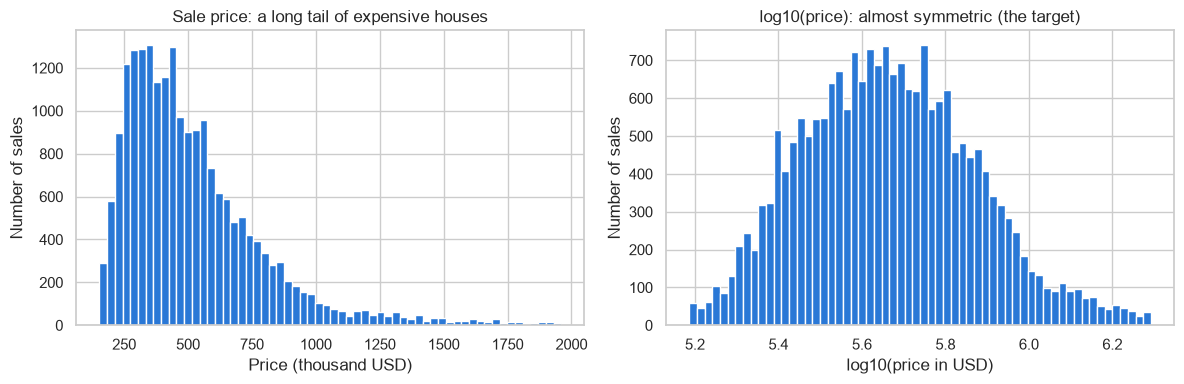

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(houses[TARGET] / 1000, bins=60, color="#2a78d6")
axes[0].set(title="Sale price: a long tail of expensive houses", xlabel="Price (thousand USD)", ylabel="Number of sales")
axes[1].hist(y, bins=60, color="#2a78d6")
axes[1].set(title="log10(price): almost symmetric (the target)", xlabel="log10(price in USD)", ylabel="Number of sales")
plt.tight_layout()
save_fig("00_target_distribution")
plt.show()

**Reading.** The raw price has a long tail to the right (skewness 1.72, against 0.28 after the log): a few expensive houses would dominate a squared-error loss. On the log scale the distribution is close to symmetric, so every house counts in proportion to its price. Most sales lie between log10 = 5.4 and 6.0, that is between about 250,000 and 1,000,000 USD.

## 1.3 Split before anything else

The brief asks for a **training**, a **validation** and a **test** set, and for **the same test set as our Day 2 model**.

- **Test set (20%) – exactly the Day 2 split.** Day 2 used `GroupShuffleSplit(test_size=0.2, random_state=42)` with the house `id` as the group: 148 houses were sold twice, and both sales must stay on the same side of the split, or the model would be tested on a house it has already seen. We repeat this call with the same data, so we get **the same 4,147 test sales** as on Day 2. The test set is then locked away until section 6.
- **Validation set (20% of the rest).** A network is trained for many epochs, so we need a separate set to watch the training, choose when to stop and compare settings (sections 3 to 5). We cut it from the Day 2 training set in the same way, grouped by `id`.

In [9]:
# 1) The Day 2 split: same call, same data, same random_state -> same test set
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(outer.split(X, y, groups))

# 2) Validation set: 20% of the Day 2 training set, again grouped by house id
inner = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_pos, val_pos = next(inner.split(X.iloc[trainval_idx], y.iloc[trainval_idx], groups.iloc[trainval_idx]))
train_idx, val_idx = trainval_idx[train_pos], trainval_idx[val_pos]

X_trainval, y_trainval = X.iloc[trainval_idx], y.iloc[trainval_idx]   # = the Day 2 training set
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]                   # locked away until section 6

split_sizes = pd.DataFrame({
    "sales": [len(train_idx), len(val_idx), len(test_idx)],
    "share": [len(train_idx) / len(X), len(val_idx) / len(X), len(test_idx) / len(X)],
    "median price (USD)": [10 ** y_train.median(), 10 ** y_val.median(), 10 ** y_test.median()],
}, index=["train", "validation", "test"])

# Checks: the same test set as Day 2 (4,147 sales), and no house on two sides of a split
assert len(test_idx) == 4147 and len(trainval_idx) == 16556, "not the Day 2 split"
sets = {name: set(groups.iloc[idx]) for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
print("Same test set as Day 2: 4,147 sales. No house appears in two sets.")
split_sizes.style.format({"sales": "{:,}", "share": "{:.1%}", "median price (USD)": "{:,.0f}"})

Same test set as Day 2: 4,147 sales. No house appears in two sets.


,sales,share,median price (USD)
train,"13,244",64.0%,"450,000"
validation,"3,312",16.0%,"459,700"
test,"4,147",20.0%,"450,000"


**Reading.** 13,244 sales for training (64%), 3,312 for validation (16%) and 4,147 for the test (20%). The median price is almost the same in the three sets (450,000, 459,700 and 450,000 USD), so none of them is cheaper or more expensive by accident.

## 1.4 Preprocessing: scaled numbers and a one-hot ZIP code

A neural network is very sensitive to the **scale** of its inputs: without scaling, `sqft_lot` (values up to about 1,000,000) would dominate `bathrooms` (1 to 5). So:

- the **12 numeric columns** are standardised with a `StandardScaler` (mean 0, standard deviation 1);
- **`zipcode`** is a category, not a quantity (98103 is not "bigger" than 98023), so it is **one-hot encoded**, as on Day 2: one 0/1 column per ZIP code.

The preprocessor is **fitted on the training set only**: the validation and test sets are transformed with the training statistics, so no information leaks from them. This fitted object is what we will publish next to the weights as `scaler.joblib` (section 8): a user must prepare a new house in exactly the same way.

In [10]:
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC_COLUMNS),
    ("zipcode", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAL_COLUMNS),
])
preprocess.fit(X_train)                                  # learned on the training set only

N_INPUTS = len(preprocess.get_feature_names_out())
print(f"{len(NUMERIC_COLUMNS)} scaled numeric columns + {N_INPUTS - len(NUMERIC_COLUMNS)} ZIP-code columns "
      f"= {N_INPUTS} inputs to the network")

check = pd.DataFrame(preprocess.transform(X_train)[:, :len(NUMERIC_COLUMNS)], columns=NUMERIC_COLUMNS)
check.describe().loc[["mean", "std"]].round(3)

12 scaled numeric columns + 70 ZIP-code columns = 82 inputs to the network


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_basement,yr_built,yr_renovated,lat,long
mean,0.000,0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


## 1.5 Convert to tensors

PyTorch works with **tensors**: `float32` for the inputs, and the target as a column of shape `(n, 1)`, because the network will have **one output neuron** (one predicted value per house).

In [11]:
def to_tensors(X_part, y_part):
    # Preprocessed inputs as float32, target log10(price) as a float32 column (n, 1)
    return (torch.tensor(preprocess.transform(X_part), dtype=torch.float32),
            torch.tensor(y_part.to_numpy(), dtype=torch.float32).reshape(-1, 1))


X_train_t, y_train_t = to_tensors(X_train, y_train)
X_val_t, y_val_t = to_tensors(X_val, y_val)
X_test_t, y_test_t = to_tensors(X_test, y_test)          # used once, in section 6
print(f"train {tuple(X_train_t.shape)}, validation {tuple(X_val_t.shape)}, test {tuple(X_test_t.shape)}")

train (13244, 82), validation (3312, 82), test (4147, 82)


# 2. Baseline

The network must beat something to be worth its extra complexity. We use two baselines, both evaluated with the same metrics:

1. **Dummy model:** always predicts the average `log10(price)` of the training set. It knows nothing about the houses; any useful model must be far better.
2. **Our Day 2 model:** `HistGradientBoostingRegressor` with its default settings, inside the Day 2 pipeline (median imputation, one-hot ZIP code, no scaling: trees do not need it). It was the model we selected on Day 2.

**Metrics** (on `log10(price)`, the same as Day 2):
- **R²**: the share of the variation in log-prices explained by the model (1 = perfect, 0 = no better than the average).
- **MAE (log10)** and the **typical error in %** it implies: 10^MAE − 1.
- **MAE in USD**, after converting the predictions back to prices, for readers who think in dollars.

We evaluate each baseline twice:
- on the **validation set**, after fitting on the training set only: this is the number the network will be compared with in sections 3 to 5, without touching the test set;
- on the **test set**, after fitting on the whole Day 2 training set (training + validation), exactly as on Day 2. This reproduces our published Day 2 result, and is the number the network's final test score will be compared with in section 6.

In [12]:
def evaluate(y_true_log, y_pred_log):
    # The metrics used in this notebook, from true and predicted log10(price)
    mae_log = mean_absolute_error(y_true_log, y_pred_log)
    return {
        "R² (log10)": r2_score(y_true_log, y_pred_log),
        "MAE (log10)": mae_log,
        "typical error (%)": (10 ** mae_log - 1) * 100,
        "MAE (USD)": mean_absolute_error(10 ** y_true_log, 10 ** y_pred_log),
    }


def day2_model():
    # The Day 2 pipeline: median imputation + one-hot ZIP code + gradient boosting (default settings)
    return Pipeline([
        ("preprocess", ColumnTransformer([
            ("numeric", SimpleImputer(strategy="median"), NUMERIC_COLUMNS),
            ("zipcode", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                  ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
             NOMINAL_COLUMNS),
        ])),
        ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
    ])


baselines = {"Dummy (mean price)": lambda: DummyRegressor(strategy="mean"),
             "Day 2: gradient boosting": day2_model}

rows = []
for name, make in baselines.items():
    # Validation: fit on the training set only
    on_val = make().fit(X_train, y_train)
    rows.append({"model": name, "evaluated on": "validation", **evaluate(y_val, on_val.predict(X_val))})
    # Test: fit on the whole Day 2 training set, as on Day 2
    on_test = make().fit(X_trainval, y_trainval)
    rows.append({"model": name, "evaluated on": "test", **evaluate(y_test, on_test.predict(X_test))})
    if name.startswith("Day 2"):
        day2_final = on_test                                  # kept for the comparison in section 6

baseline_results = pd.DataFrame(rows).set_index(["model", "evaluated on"])
baseline_results.style.format({"R² (log10)": "{:.3f}", "MAE (log10)": "{:.4f}",
                               "typical error (%)": "{:.1f}", "MAE (USD)": "{:,.0f}"})

**Reading.**

- **We reproduce our Day 2 result:** on the Day 2 test set, gradient boosting reaches **R² = 0.886**, exactly the test score we published on Day 2. This confirms that the test set and the model are the same.
- **The bar to beat:** on the test set the Day 2 model is typically **12.2% off** the true price (a mean error of about 60,200 USD), against **47.0%** (about 196,300 USD) for the dummy model, which always predicts the average.
- **On the validation set** the Day 2 model reaches R² = 0.892 and a typical error of 11.9%. Validation and test scores are close, so the validation set is a fair stand-in for the test set while we train and tune the network: **a network with a validation error below about 12% would beat our Day 2 model.**
- **The question for the next sections:** gradient boosting is very strong on tables with a handful of meaningful columns. Notebook 01 found that a network was *slightly worse* than gradient boosting on the energy dataset. We will see whether the same happens here.

Figure saved to ..\figures\00_baselines.png


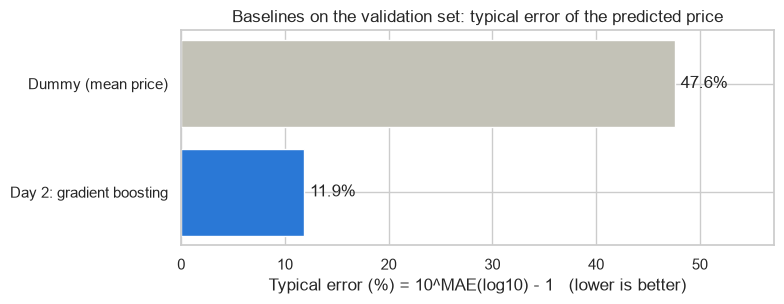

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
val_scores = baseline_results.xs("validation", level="evaluated on")["typical error (%)"]
bars = ax.barh(val_scores.index, val_scores.values, color=["#c3c2b7", "#2a78d6"])
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.set(title="Baselines on the validation set: typical error of the predicted price",
       xlabel="Typical error (%) = 10^MAE(log10) - 1   (lower is better)", xlim=(0, val_scores.max() * 1.2))
ax.invert_yaxis()
plt.tight_layout()
save_fig("00_baselines")
plt.show()

## Hand-off to the next sections

Everything the next sections need is ready. **Do not refit `preprocess` or change the splits**: the comparison with Day 2 depends on them.

- **`X_train_t`, `y_train_t`**: the training set as tensors (13,244 sales × `N_INPUTS` inputs; target `log10(price)` of shape (n, 1)). The network learns from these.
- **`X_val_t`, `y_val_t`**: the validation set (3,312 sales), to draw the training curves, stop early and compare settings.
- **`X_test_t`, `y_test_t`**: the test set (4,147 sales, the Day 2 test set). **Use it only once, in section 6.**
- **`X_train`, `X_val`, `X_test`** (and `y_...`): the same sets as pandas tables, in original units, for plots and for the application.
- **`N_INPUTS`**: the number of inputs of the network (82: 12 scaled numbers + 70 ZIP-code columns).
- **`preprocess`**: the fitted scaler + one-hot encoder. Save it as `models/scaler.joblib` in section 8.
- **`evaluate(y_true_log, y_pred_log)`**: returns R², MAE (log10), typical error (%) and MAE (USD), so every model is compared with the same metrics.
- **`baseline_results`** and **`day2_final`**: the baseline scores, and the Day 2 model fitted on the whole Day 2 training set, for the final comparison in section 6.
- **`DEVICE`**, **`RANDOM_STATE`** and **`save_fig(name, also_to_models=True)`**: the device, the seed, and a helper that saves a figure in `figures/` (and in `models/` for the model card).

Figures `00_target_distribution` and `00_baselines` are in `figures/`; the next sections can continue from `01_`.